# 02 — Data cleaning: every decision, stated and defended

**Purpose.** The processed catalog (`data/processed/earthquakes.parquet`) is the input
to every later stage of this project, so each transformation applied to it has to be
explicit, justified, and reproducible. This notebook restates those decisions against
the data itself rather than against a spec.

**Project rule (repeated here because it is load-bearing):**
*missingness is measured, never blindly filled.* See section 2.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

# The build tool executes the kernel with cwd = notebooks/; move to the repository root
# so every relative path below follows the documented repo-root convention.
if not Path("data").exists():
    os.chdir(Path.cwd().parent)
assert Path("data/processed/earthquakes.parquet").exists(), "run from the repository root"

NAVY = "#14263D"
ACCENT = "#2583A6"
LIGHT = "#E9EEF3"

plt.rcParams.update(
    {
        "figure.figsize": (9, 5),
        "figure.dpi": 150,
        "savefig.dpi": 150,
        "font.size": 11,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.labelsize": 11,
        "axes.edgecolor": NAVY,
        "axes.labelcolor": NAVY,
        "text.color": NAVY,
        "xtick.color": NAVY,
        "ytick.color": NAVY,
        "axes.grid": True,
        "grid.color": LIGHT,
        "axes.axisbelow": True,
        "legend.frameon": False,
        "savefig.bbox": "tight",
        "savefig.facecolor": "white",
    }
)

FIG_DIR = Path("reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)


def save(fig, name: str) -> Path:
    """Write reports/figures/<name>, embed it in the notebook, free the memory."""
    path = FIG_DIR / name
    fig.savefig(path, dpi=150)
    plt.close(fig)
    display(Image(filename=str(path)))
    return path


df = pd.read_parquet("data/processed/earthquakes.parquet")
print(f"processed shape: {df.shape[0]:,} rows x {df.shape[1]} columns")

processed shape: 707,438 rows x 24 columns


## 1. Event-type filtering: only earthquakes are kept

The raw store mixes seismic **earthquakes** with every other event type ComCat
indexes: explosions, mining blasts, quarry blasts, ice quakes, landslides, nuclear
tests, sonic booms. Counting `type` across all 323 raw files (715,183 rows) shows
exactly what was dropped.

In [2]:
raw_files = sorted(Path("data/raw").glob("*.parquet"))
raw_types = pd.concat(
    (pd.read_parquet(p, columns=["type"]) for p in raw_files),
    ignore_index=True,
)["type"]
print(f"raw rows read: {len(raw_types):,} from {len(raw_files)} files")

type_counts = raw_types.value_counts()
non_earthquake = type_counts.drop(labels=["earthquake"])
print(f"\nnon-earthquake events removed: {non_earthquake.sum():,}")
print(f"distinct non-earthquake types: {len(non_earthquake)}")
print(non_earthquake.to_string())

raw rows read: 715,183 from 323 files

non-earthquake events removed: 7,745
distinct non-earthquake types: 19
type
explosion                     4262
mining explosion              2809
ice quake                      219
rock burst                     134
other event                    130
volcanic eruption               74
quarry blast                    63
mine collapse                   15
experimental explosion          11
landslide                        8
nuclear explosion                6
sonic boom                       6
Landslide                        2
Rock Slide                       1
acoustic noise                   1
collapse                         1
induced or triggered event       1
Ice Quake                        1
accidental explosion             1


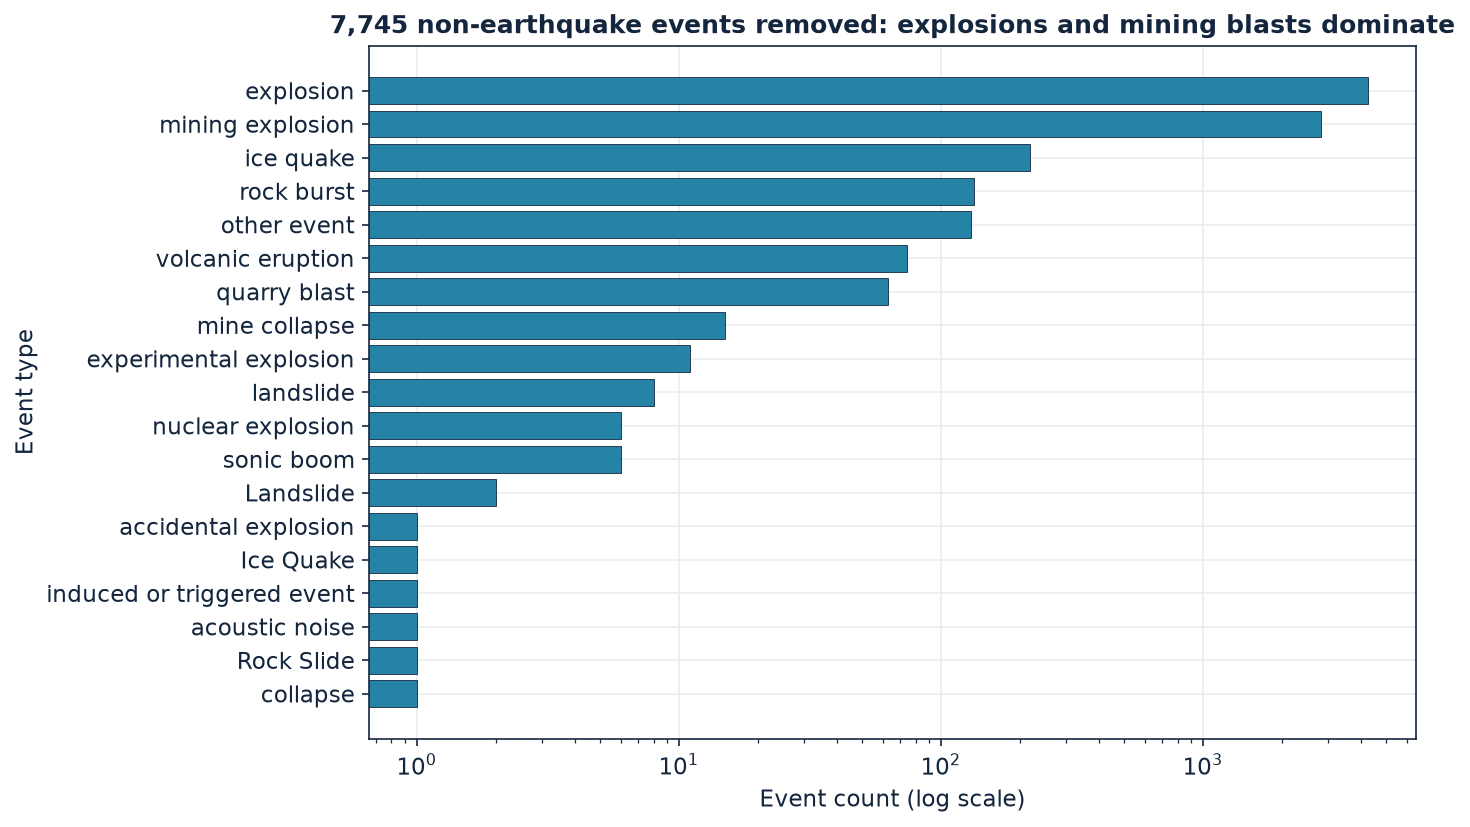

processed type breakdown:
type
earthquake    707438


In [3]:
fig, ax = plt.subplots(figsize=(9, 6))
plot_counts = non_earthquake.sort_values()
ax.barh(plot_counts.index, plot_counts.values, color=ACCENT, edgecolor=NAVY, linewidth=0.4)
ax.set_xscale("log")
ax.set_title("7,745 non-earthquake events removed: explosions and mining blasts dominate")
ax.set_xlabel("Event count (log scale)")
ax.set_ylabel("Event type")
save(fig, "eda_event_types_removed.png")

kept = df["type"].value_counts()
print("processed type breakdown:")
print(kept.to_string())
assert set(kept.index) == {"earthquake"}, "processed data must contain only earthquakes"

**Decision.** Keep `type == "earthquake"` only (707,438 rows), drop the other 19
types (7,745 rows, 1.08% of raw). A quarry blast and a magnitude-4 earthquake can look
identical to a magnitude scale, but they are not the same population: mixing them
would inflate regional counts (e.g. `mining explosion`, 2,809 events) and distort the
frequency-magnitude statistics that notebook 03 depends on.

## 2. Missingness: measured, never blindly filled

Quality fields are the most heavily missing columns in the catalog. The chart below is
computed from the processed data — it is a measurement, not an assumption.

In [4]:
missing = df.isna().sum().to_frame("missing_rows")
missing["pct"] = 100 * missing["missing_rows"] / len(df)
missing = missing.sort_values("pct", ascending=False)
print(missing.round(3).to_string())

                 missing_rows     pct
dmin                   362699  51.269
horizontalError        357808  50.578
magError               356234  50.356
nst                    232598  32.879
magNst                 210391  29.740
depthError             208746  29.507
gap                    116726  16.500
rms                    107590  15.208
place                       1   0.000
magType                     1   0.000
mag                         0   0.000
depth                       0   0.000
time                        0   0.000
latitude                    0   0.000
longitude                   0   0.000
id                          0   0.000
type                        0   0.000
updated                     0   0.000
net                         0   0.000
status                      0   0.000
locationSource              0   0.000
magSource                   0   0.000
year                        0   0.000
month                       0   0.000


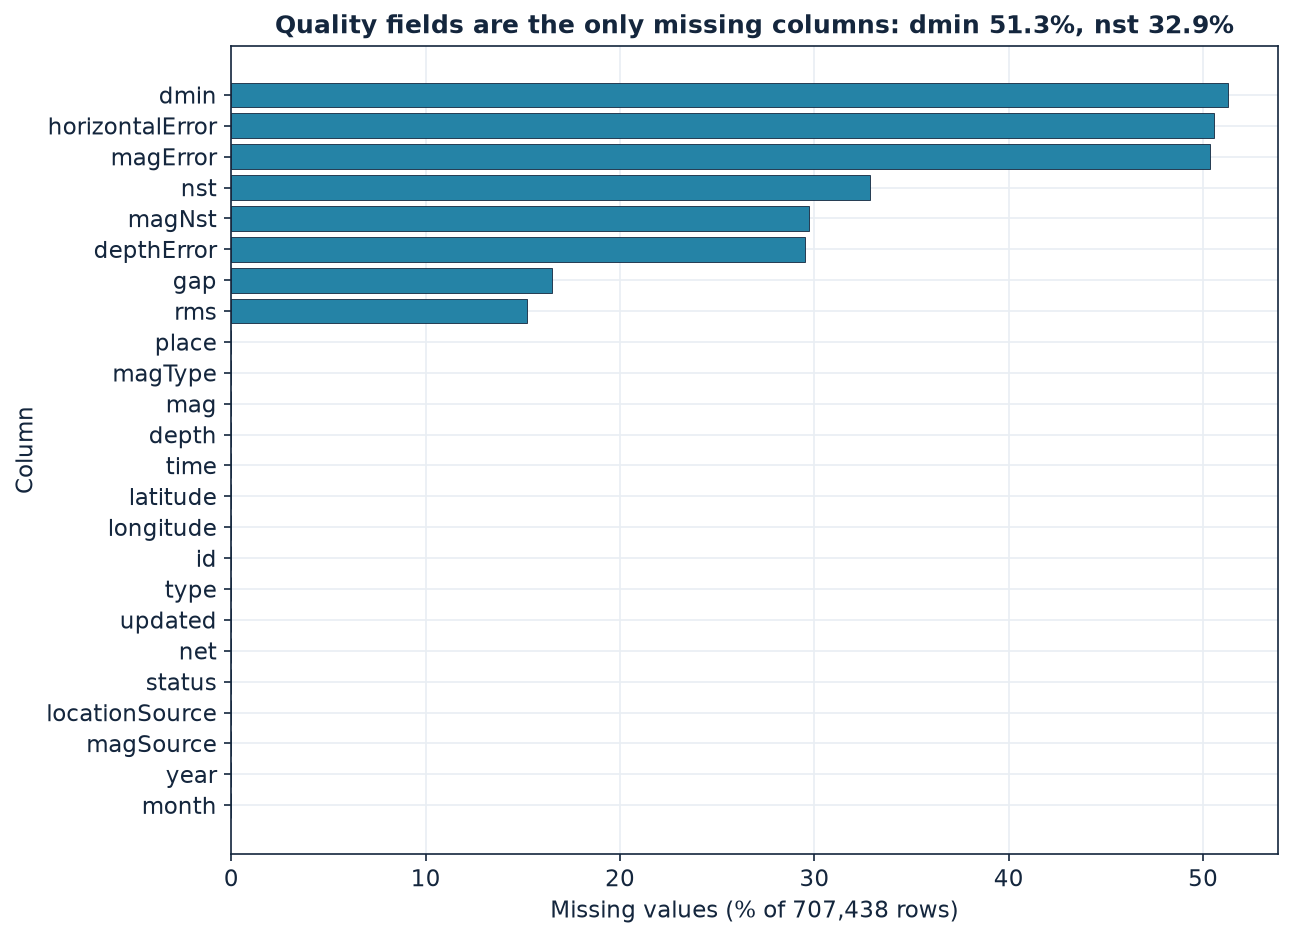

PosixPath('reports/figures/eda_missingness.png')

In [5]:
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(missing.index[::-1], missing["pct"].values[::-1], color=ACCENT,
        edgecolor=NAVY, linewidth=0.4)
ax.set_title("Quality fields are the only missing columns: dmin 51.3%, nst 32.9%")
ax.set_xlabel("Missing values (% of 707,438 rows)")
ax.set_ylabel("Column")
save(fig, "eda_missingness.png")

### The rule: missingness is measured, never blindly filled

**No column in this project is mean-, median- or zero-imputed.** The reason is that
the missing values are *informative about the observation process*, not about the
earthquake:

* `nst` (number of reporting stations, 32.9% missing), `gap` (azimuthal gap, 16.5%),
  `dmin` (nearest-station distance, 51.3%) and `rms` (15.2%) are **network-dependent**.
  They exist only when enough stations reported to the contributing network. An empty
  `dmin` does not mean "stations were far away"; it usually means the solution was
  produced without one being recorded.
* Filling these with a constant would fabricate instrument information: every imputed
  row would claim, falsely, that a specific network geometry was observed. Downstream
  models would then learn from invented metadata instead of from data.
* The same applies to `horizontalError` (50.6% missing), `magError` (50.4%) and
  `depthError` (29.5%): they are reported for some solution types and not others, so
  their absence is a property of the *solution*, not of the event.

The defensible alternatives are (a) leave as `NaN` and let each analysis decide what to
do with them, or (b) restrict to the subset where the field exists — both keep the
provenance honest. This project does (a), and reports coverage whenever a quality
field is used.

Core event fields (`time`, `latitude`, `longitude`, `depth`, `mag`, `id`) have **0**
missing rows, so no imputation is needed for the scientific variables themselves.

In [6]:
core = ["time", "latitude", "longitude", "depth", "mag", "id", "updated", "year", "month"]
core_missing = df[core].isna().sum()
print("missing rows in core scientific columns:")
print(core_missing.to_string())
print(f"\ntotal core missing: {int(core_missing.sum())}")

missing rows in core scientific columns:
time         0
latitude     0
longitude    0
depth        0
mag          0
id           0
updated      0
year         0
month        0

total core missing: 0


## 3. Negative depths: 4,359 events kept on purpose

`depth` is in kilometres below sea level, so a small negative value means the
hypocentre is *above* sea level — a near-surface event. These are real, reviewed
locations for shallow volcanic, mining and quarry-related seismicity recorded by
networks that report elevations relative to sea level rather than to a local datum.

In [7]:
neg = df.loc[df["depth"] < 0, "depth"]
print(f"negative depths: {len(neg):,} rows ({100 * len(neg) / len(df):.2f}%)")
print(f"range: {neg.min():.2f} km … {neg.max():.2f} km, median {neg.median():.2f} km")
print(f"rows with depth exactly 0: {(df['depth'] == 0).sum():,}")
print("\nshallowest 5 events:")
cols = ["time", "depth", "mag", "net", "place"]
print(df.nsmallest(5, "depth")[cols].to_string(index=False))

negative depths: 4,359 rows (0.62%)
range: -3.74 km … -0.00 km, median -0.71 km
rows with depth exactly 0: 3,964

shallowest 5 events:
                         time  depth  mag net                                place
2022-11-28 08:59:21.000+00:00  -3.74 3.72  hv 26 km E of Honaunau-Napoopoo, Hawaii
2018-07-24 02:44:48.200+00:00  -3.65 2.68  hv          25 km NNW of Pāhala, Hawaii
2022-08-06 11:39:07.020+00:00  -3.63 2.81  hv             Island of Hawaii, Hawaii
2022-11-28 18:57:50.840+00:00  -3.57 3.01  hv           29 km W of Volcano, Hawaii
2024-12-12 12:06:26.630+00:00  -3.50 2.55  uu    1 km N of Little America, Wyoming


**Decision: retain, do not delete.** Dropping them would (a) remove 4,359 genuine
events — 0.62% of the catalog — biased towards volcanically and industrially active
regions, and (b) silently redefine `depth` as "depth below sea level, except when we
do not like the answer". Nothing downstream needs strictly positive depths: the depth
analyses in notebook 03 bin them explicitly and label the negative bin.

## 4. The five events below the M2.5 threshold: the catalog is a living document

The query asked for `minmagnitude = 2.5`, yet the processed magnitude range starts at
**0.7**. Five events sit below the threshold. They are not a filtering bug — they are
evidence that ComCat records are *revised after they are indexed*.

In [8]:
below = df.loc[df["mag"] < 2.5, ["time", "updated", "mag", "magType", "net", "id", "place"]]
print(f"events with mag < 2.5: {len(below)}")
print(below.to_string(index=False))

events with mag < 2.5: 5
                         time                       updated  mag magType net         id                                       place
2014-02-07 15:45:06.510+00:00 2021-05-13 21:59:17.902+00:00 2.42      ml  ld ld60063426               15 km NNW of Mooers, New York
2014-02-13 04:57:38.020+00:00 2021-05-13 21:59:18.980+00:00 2.46      ml  ld ld60064321            34 km N of Lyndonville, New York
2015-01-19 16:35:14.690+00:00 2021-05-13 21:59:44.501+00:00 2.12      ml  ld ld60086101 6 km SW of Salaberry-de-Valleyfield, Canada
2017-02-07 18:46:43.770+00:00 2023-08-04 19:30:20.172+00:00 0.70      ml  us us20008ia2                              Central Alaska
2018-08-19 01:49:39.520+00:00 2023-08-16 15:45:17.201+00:00 1.90      ml  us us1000gcqs        123 km NNW of Arctic Village, Alaska


In [9]:
revised = (below["updated"] - below["time"]).dt.total_seconds() / (365.25 * 24 * 3600)
print("years between event and its last catalog revision:")
print(revised.round(1).to_string(index=False))

years between event and its last catalog revision:
7.3
7.2
6.3
6.5
5.0


**Explanation.** The web-service filter is evaluated against the magnitude stored in
the event *index* at query time, while the `mag` field returned for an event is its
current **preferred** magnitude. When a reviewer re-solves an event after it has been
indexed and the revised magnitude comes back below 2.5, the event still passes the
M2.5 filter but is delivered with `mag < 2.5`. All five are `reviewed` solutions whose
`updated` timestamps postdate the event — e.g. `us20008ia2` (Central Alaska) was
indexed above threshold and later revised down to M0.70.

Consequences for this project:

* the collection threshold is a **query-time** property, not a guarantee about every
  row — so completeness statements must be made from the observed distribution
  (notebook 03), not from the request parameters;
* the catalog is a living document: any future re-run may return slightly different
  rows for the same query, which is exactly why the manifest records per-month
  sha256 checksums (notebook 01).

## 5. Duplicate handling: unique ids, latest revision wins

The ComCat event `id` is the natural primary key. The cleaning rule was:
*if the same `id` appears more than once, keep the row with the latest `updated`
timestamp* (the most recent catalog revision). The check below confirms the rule's
effect on this run.

In [10]:
n_dup_ids = int(df["id"].duplicated().sum())
print(f"rows: {len(df):,}")
print(f"distinct ids: {df['id'].nunique():,}")
print(f"duplicate ids remaining: {n_dup_ids}")

# Apply the documented rule explicitly; with zero duplicates it must be a no-op.
deduped = (
    df.sort_values("updated").drop_duplicates(subset="id", keep="last").sort_index()
)
print(f"rows after applying keep-latest-updated rule: {len(deduped):,}")
assert len(deduped) == len(df), "keep-latest-updated rule must not change row count"

# Near-duplicates on time+location are a different (and much rarer) phenomenon.
key = (
    df["time"].astype("int64").astype(str)
    + "|"
    + df["latitude"].round(3).astype(str)
    + "|"
    + df["longitude"].round(3).astype(str)
)
print(f"rows sharing identical (time, lat, lon): {int(key.duplicated(keep=False).sum())}")
print("  (distinct networks can catalogue the same quake under different ids)")

rows: 707,438


distinct ids: 707,438
duplicate ids remaining: 0


rows after applying keep-latest-updated rule: 707,438


rows sharing identical (time, lat, lon): 28
  (distinct networks can catalogue the same quake under different ids)


## 6. What the processed dataset guarantees

After the cleaning stage, `data/processed/earthquakes.parquet` (707,438 rows × 24
columns) satisfies all of the following — each claim is checked above or in
`reports/data_quality/data_quality.json` (which records zero hard violations):

1. **Earthquakes only** — every row has `type == "earthquake"`; 7,745 non-earthquake
   events were removed from the 715,183 raw rows.
2. **One row per event** — `id` is unique (0 duplicates); where an id did repeat, the
   latest `updated` revision would be kept (rule verified as a no-op here).
3. **Bounded coverage** — event times from 2000-01-01 to 2026-11-15, magnitudes 0.7 to
   9.1, depths −3.74 km to 735.8 km; the 5 sub-threshold magnitudes are documented
   revisions, not filter failures.
4. **Honest missingness** — quality fields (`dmin` 51.3%, `nst` 32.9%, `gap` 16.5%,
   `rms` 15.2%, …) are left as `NaN`; nothing is imputed.
5. **Negative depths retained** — 4,359 near-surface events kept and labelled, not
   deleted.
6. **Derived keys present** — `year` and `month` are precomputed for temporal
   analysis; `latitude`/`longitude`/`depth`/`mag`/`time` have zero missing values.

What it does *not* guarantee: uniform detection. Completeness varies by region and by
era, and that caveat governs every interpretation in notebook 03.